In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops

# Step 1: Load image
image = cv2.imread('../Data/Dog.jpg')

if image is None:
    raise FileNotFoundError("Check the path: ../Data/Dog.jpg")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

In [ ]:
# Step 2: Ensure grayscale image is 2D
gray = np.squeeze(gray)
print("Gray shape:", gray.shape)

In [21]:
# Step 3: Quantize image into 16 gray levels
quantized = (gray // 16).astype(np.uint8)
print("Quantized shape:", quantized.shape)

Quantized shape: (602, 1200)


In [17]:
# Step 2: Reduce gray levels from 256 to 16
quantized = (image // 16).astype(np.uint8)
# Verify the image dimensions
print("Gray image shape:", gray.shape)
print("Quantized image shape:", quantized.shape)
print("Number of dimensions:", quantized.ndim)

Gray image shape: (602, 1200)
Quantized image shape: (602, 1200, 3)
Number of dimensions: 3


In [22]:
# Step 4: Calculate GLCM
glcm = graycomatrix(
    quantized,
    distances=[1],
    angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
    levels=16,
    symmetric=True,
    normed=True
)

In [23]:
# Step 5: Calculate texture features
for feature in ["contrast", "dissimilarity", "homogeneity",
                "energy", "correlation"]:
    value = np.mean(graycoprops(glcm, feature))
    print(f"{feature.capitalize()}: {value:.4f}")

Contrast: 0.2462
Dissimilarity: 0.1803
Homogeneity: 0.9160
Energy: 0.3680
Correlation: 0.9670


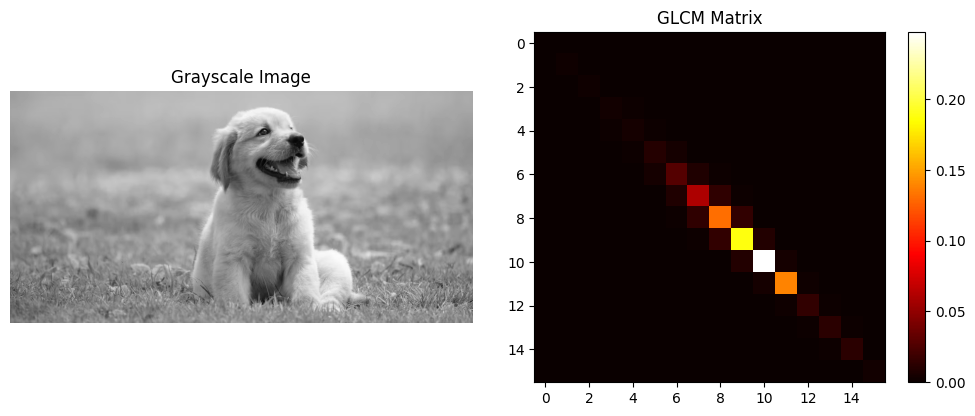

In [24]:
# Step 6: Display results
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(glcm[:, :, 0, 0], cmap="hot")
plt.title("GLCM Matrix")
plt.colorbar()

plt.tight_layout()
plt.show()
